# 17. Estudo com as séries clássicas de benchmark

**Objetivo e requisitos.** Comparar modelos individuais e híbridos em 17 séries clássicas do Rdatasets, separadas em três classes (estacionárias, maior e menor força sazonal): cinco modelos, entre eles o híbrido ARIMA–ANN, avaliados nos protocolos A (12 passos de uma vez) e B (um passo por vez), com 3, 6 e 12 lags, erro por classe, curvas por horizonte, contraste híbrido × base e custo. Não há busca nem campeão: cada modelo é ajustado uma vez no histórico anterior ao teste e avaliado uma vez no teste. Extras `stats` e `plot`; baixa as séries na primeira execução.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.data.characterization import characterize
from autohybts.datasets import raw_dataset
from autohybts.domain.specs import CandidateSpec, ModelSpec
from autohybts.reporting.comparison import holm

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Dados e protocolo

Regras do estudo: teste de 12 pontos (erro resumido nos horizontes 1, 3, 6 e 12), ao menos 60 observações e nenhum salto relativo acima de 100 % antes do teste. Cada série recebe um índice diário sintético (a frequência original não entra nos modelos); o período sazonal dos modelos é 12.

In [2]:
CATALOG = {
    "air_passengers": "AirPassengers",
    "australian_residents": "austres",
    "bj_sales": "BJsales",
    "us_accidental_deaths": "USAccDeaths",
    "discoveries": "discoveries",
    "johnson_johnson": "JohnsonJohnson",
    "lake_huron": "LakeHuron",
    "female_lung_deaths": "fdeaths",
    "lynx": "lynx",
    "nile": "Nile",
    "nottingham_temperature": "nottem",
    "northern_hemisphere_temperature": "nhtemp",
    "sunspot_year": "sunspot.year",
    "monthly_sunspots": "sunspots",
    "tree_ring": "treering",
    "uk_driver_deaths": "UKDriverDeaths",
    "web_usage": "WWWusage",
}
H = 12
HORIZONS = [1, 3, 6, 12]


def max_relative_jump(values):
    level = np.maximum(np.abs(values[1:]), np.abs(values[:-1]))
    jumps = np.divide(
        np.abs(np.diff(values)), level, out=np.zeros(len(values) - 1), where=level > 0
    )
    return float(jumps.max())


series = {}
for sid, name in CATALOG.items():
    values = raw_dataset("rdatasets", package="datasets", name=name)["value"].to_numpy(float)
    series[sid] = pd.Series(
        values, index=pd.date_range("2000-01-01", periods=len(values), freq="D"), name=sid
    )
series = {
    sid: y
    for sid, y in series.items()
    if len(y) >= 60 and max_relative_jump(y.to_numpy()[:-H]) <= 1.0
}
print("séries elegíveis:", len(series))

séries elegíveis: 17


## 2. Exploração causal

Duas regras no trecho antes do teste: ADF decide se a série é estacionária; nas demais, a força da STL robusta sobre a série Box-Cox (períodos 4 e 12) separa a de maior força sazonal (acima de 0,5) da de menor. Todas as séries elegíveis entram no estudo.

In [3]:
selection = pd.DataFrame(
    {sid: characterize(y.to_numpy()[:-H], (4, 12)) for sid, y in series.items()}
).T
selection = selection[
    ["n", "adf_stat_d0", "adf_pvalue_d0", "diff_order", "fs_4", "fs_12", "fs", "category"]
]
CAT = {
    "stationary": "Estacionárias",
    "seasonal": "Maior força sazonal",
    "nonseasonal": "Menor força sazonal",
}
selection.sort_values(["category", "fs"])

,n,adf_stat_d0,adf_pvalue_d0,diff_order,fs_4,fs_12,fs,category
australian_residents,77,2.219085,0.998898,2,0.0,0.0,0.0,nonseasonal
bj_sales,138,-1.091853,0.71831,1,0.0,0.0,0.0,nonseasonal
lake_huron,86,-2.837671,0.053091,1,0.189103,0.26618,0.26618,nonseasonal
lynx,102,-2.710587,0.072224,1,0.026964,0.275202,0.275202,nonseasonal
web_usage,88,-2.842188,0.052496,2,0.005612,0.282459,0.282459,nonseasonal
northern_hemisphere_temperature,48,-2.704231,0.073309,1,0.262481,0.381753,0.381753,nonseasonal
uk_driver_deaths,180,-0.063104,0.952992,1,-0.032983,0.765658,0.765658,seasonal
johnson_johnson,72,3.515816,1.0,2,0.837438,0.705074,0.837438,seasonal
air_passengers,132,0.888027,0.992932,2,-0.17221,0.957727,0.957727,seasonal
us_accidental_deaths,60,-4.715744,0.000079,0,NaN,NaN,NaN,stationary


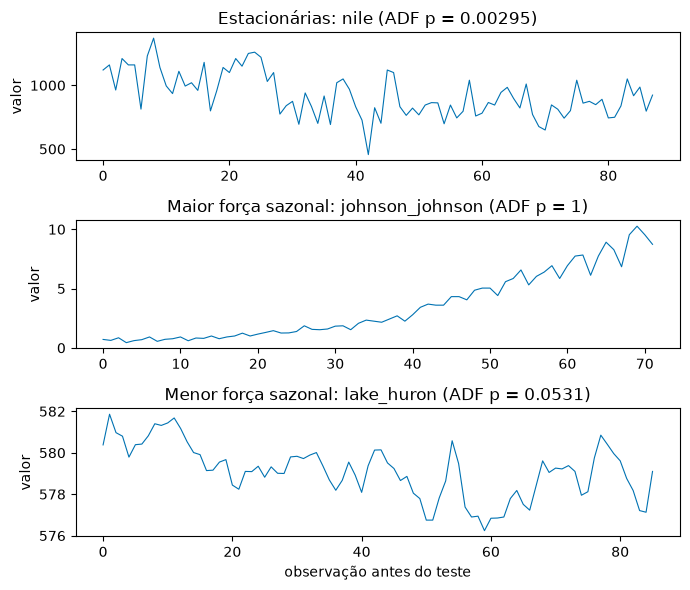

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(7, 6))
for ax, (category, title) in zip(axes, CAT.items(), strict=True):
    group = selection[selection.category == category].sort_values("fs", na_position="first")
    sid = group.index[(len(group) - 1) // 2]
    ax.plot(series[sid].to_numpy()[:-H], color="#0072B2", linewidth=0.8)
    ax.set(
        title=f"{title}: {sid} (ADF p = {selection.loc[sid, 'adf_pvalue_d0']:.3g})", ylabel="valor"
    )
axes[-1].set_xlabel("observação antes do teste")
fig.tight_layout()
plt.show()

## 3. Controles e modelos propostos

Cinco modelos: a persistência como controle; ETS e ARIMA, sem lags; KNN com 3, 6 e 12 lags; e o híbrido ARIMA–ANN, em que um corretor MLP (5 neurônios, ativação logística, lbfgs) prevê o erro do ARIMA a partir de janelas de 3, 6 e 12 resíduos fora da amostra. Cada configuração é identificada pelo modelo e pelo número de lags (`knn_6`, `arima_ann_12`); o híbrido é comparado com a sua base, o ARIMA.

In [5]:
LAGS = [3, 6, 12]
FIXED = {
    "naive": ("naive", {}, "statistical"),
    "ets": ("exponential_smoothing", {"season_length": 12}, "statistical"),
    "arima": ("arima", {}, "statistical"),
}
LAGGED = {"knn": "kernel"}
PAIRS = [("arima_ann", "arima")]
ANN = {
    "random_state": 42,
    "estimator_params": {
        "hidden_layer_sizes": [5],
        "activation": "logistic",
        "solver": "lbfgs",
        "max_iter": 2000,
    },
}


def specs(variant):
    """(structure, lags) -> specification; lags = 0 for the models without lags."""
    out = {
        (structure, 0): CandidateSpec.standalone(name, params, family=family, variant=variant)
        for structure, (name, params, family) in FIXED.items()
    }
    for lags in LAGS:
        for structure, family in LAGGED.items():
            out[structure, lags] = CandidateSpec.standalone(
                structure, {"lags": lags}, family=family, variant=variant
            )
        for hybrid, base in PAIRS:
            name, params, _ = FIXED[base]
            out[hybrid, lags] = CandidateSpec(
                "residual",
                "residual_additive",
                ModelSpec.of(name, params),
                ModelSpec.of("mlp", ANN),
                lags,
                1.0,
                "historical_oof_1step",
                variant=variant,
            )
    return out


print(len(specs("A")), "modelos por protocolo")

9 modelos por protocolo


## 4. Ajuste e avaliação

Para cada série e protocolo, um experimento sela os 12 pontos finais. Cada modelo é reajustado no histórico anterior e lido uma única vez no teste: em A, os 12 passos saem de uma vez; em B, são 12 previsões de um passo, cada valor revelado depois da sua previsão e sem reajuste. O erro é o RRMSE acumulado até cada horizonte. Falhas são registradas e não interrompem o estudo.

In [6]:
def cumulative_rrmse(y_true, y_pred):
    h = np.arange(1, len(y_true) + 1)
    rmse = np.sqrt(np.cumsum((y_true - y_pred) ** 2) / h)
    return rmse / (np.cumsum(y_true) / h)


rows, failures = [], []
for sid, y in series.items():
    for protocol in ("A", "B"):
        exp = AutoHybridExperiment(
            fh=H if protocol == "A" else 1,
            test_size=H,
            variant=protocol,
            seasonal_period=12,
            metrics=["RRMSE", "MASE"],
            session_id=42,
        ).fit(y)
        for (structure, lags), spec in specs(protocol).items():
            started = time.perf_counter()
            try:
                predictions = exp.evaluate_external(exp.finalize_model(spec)).predictions
            except Exception as error:
                failures.append(
                    {
                        "series_id": sid,
                        "protocol": protocol,
                        "structure": structure,
                        "lags": lags,
                        "error": str(error)[:120],
                    }
                )
                continue
            seconds = time.perf_counter() - started
            curve = cumulative_rrmse(
                predictions["y_true"].to_numpy(), predictions["y_pred"].to_numpy()
            )
            model = structure if lags == 0 else f"{structure}_{lags}"
            rows += [
                {
                    "series_id": sid,
                    "protocol": protocol,
                    "structure": structure,
                    "lags": lags,
                    "model": model,
                    "h": h,
                    "rrmse": value,
                    "seconds": seconds,
                }
                for h, value in enumerate(curve, start=1)
            ]
metrics = pd.DataFrame(rows).merge(selection[["category"]], left_on="series_id", right_index=True)
final = metrics[metrics.h == H]
print(final.series_id.nunique(), "séries |", len(final), "avaliações |", len(failures), "falhas")
pd.DataFrame(failures)

17 séries | 306 avaliações | 0 falhas


""


## 5. Resultados e gráficos

RRMSE médio de cada modelo em `h = 12`, por protocolo e classe (as séries são a unidade de análise), e os três melhores de cada grupo.

In [7]:
final.pivot_table(index="model", columns=["protocol", "category"], values="rrmse").sort_values(
    ("A", "stationary")
).round(4)

protocol               A                               B                    
category     nonseasonal seasonal stationary nonseasonal seasonal stationary
model                                                                       
knn_12            0.0956   0.2249     0.3628      0.0932   0.2221     0.3033
knn_6             0.0876   0.3172     0.3750      0.0972   0.2408     0.2990
arima             0.1349   0.1719     0.4304      0.0470   0.1346     0.2931
ets               0.1390   0.1184     0.4626      0.0690   0.0783     0.2811
knn_3             0.0959   0.2561     0.4665      0.0887   0.2180     0.2931
arima_ann_12      0.1935   0.2169     0.5187      0.1474   0.1834     0.3990
arima_ann_6       0.2038   0.2617     0.5875      0.1851   0.2058     0.5188
naive             0.2034   0.2562     0.6212      0.0880   0.1578     0.3342
arima_ann_3       0.2080   0.2497     0.6395      0.1302   0.2419     0.5315

In [8]:
(
    final.groupby(["protocol", "category", "model"], as_index=False)
    .rrmse.mean()
    .sort_values("rrmse")
    .groupby(["protocol", "category"])
    .head(3)
    .sort_values(["protocol", "category", "rrmse"])
)

,protocol,category,model,rrmse
7,A,nonseasonal,knn_6,0.087648
5,A,nonseasonal,knn_12,0.095574
6,A,nonseasonal,knn_3,0.095880
13,A,seasonal,ets,0.118422
9,A,seasonal,arima,0.171893
10,A,seasonal,arima_ann_12,0.216868
23,A,stationary,knn_12,0.362759
25,A,stationary,knn_6,0.375010
18,A,stationary,arima,0.430371
27,B,nonseasonal,arima,0.047023


RRMSE médio acumulado nos horizontes 1, 3, 6 e 12, por protocolo e classe.

In [9]:
metrics[metrics.h.isin(HORIZONS)].pivot_table(
    index="model", columns=["protocol", "category", "h"], values="rrmse"
).sort_values(("A", "stationary", H)).round(3)

protocol               A                                                     \
category     nonseasonal                      seasonal                        
h                     1      3      6      12       1      3      6      12   
model                                                                         
knn_12             0.046  0.076  0.087  0.096    0.215  0.220  0.229  0.225   
knn_6              0.028  0.075  0.082  0.088    0.199  0.246  0.318  0.317   
arima              0.009  0.074  0.097  0.135    0.070  0.147  0.159  0.172   
ets                0.102  0.129  0.137  0.139    0.096  0.114  0.116  0.118   
knn_3              0.012  0.063  0.068  0.096    0.117  0.190  0.226  0.256   
arima_ann_12       0.098  0.154  0.194  0.194    0.046  0.184  0.238  0.217   
arima_ann_6        0.057  0.093  0.185  0.204    0.040  0.253  0.248  0.262   
naive              0.114  0.172  0.188  0.203    0.136  0.170  0.228  0.256   
arima_ann_3        0.061  0.150  0.163  0.208    0.036  0.160  0.245  0.250   

protocol                        ...           B                                \
category     stationary         ... nonseasonal        seasonal                 
h                    1      3   ...          6      12       1      3      6    
model                           ...                                             
knn_12            0.131  0.288  ...       0.053  0.093    0.215  0.202  0.217   
knn_6             0.127  0.301  ...       0.088  0.097    0.199  0.228  0.226   
arima             0.169  0.324  ...       0.047  0.047    0.070  0.104  0.123   
ets               0.174  0.343  ...       0.075  0.069    0.096  0.089  0.082   
knn_3             0.118  0.265  ...       0.085  0.089    0.117  0.194  0.188   
arima_ann_12      0.232  0.397  ...       0.172  0.147    0.046  0.154  0.213   
arima_ann_6       0.471  0.465  ...       0.123  0.185    0.040  0.182  0.157   
naive             0.192  0.407  ...       0.098  0.088    0.136  0.111  0.148   
arima_ann_3       0.195  0.461  ...       0.086  0.130    0.036  0.136  0.130   

protocol                                             
category            stationary                       
h                12         1      3      6      12  
model                                                
knn_12        0.222      0.131  0.244  0.239  0.303  
knn_6         0.241      0.127  0.242  0.233  0.299  
arima         0.135      0.169  0.245  0.235  0.293  
ets           0.078      0.174  0.221  0.216  0.281  
knn_3         0.218      0.118  0.190  0.216  0.293  
arima_ann_12  0.183      0.232  0.302  0.266  0.399  
arima_ann_6   0.206      0.471  0.391  0.419  0.519  
naive         0.158      0.192  0.294  0.310  0.334  
arima_ann_3   0.242      0.195  0.331  0.357  0.532  

[9 rows x 24 columns]

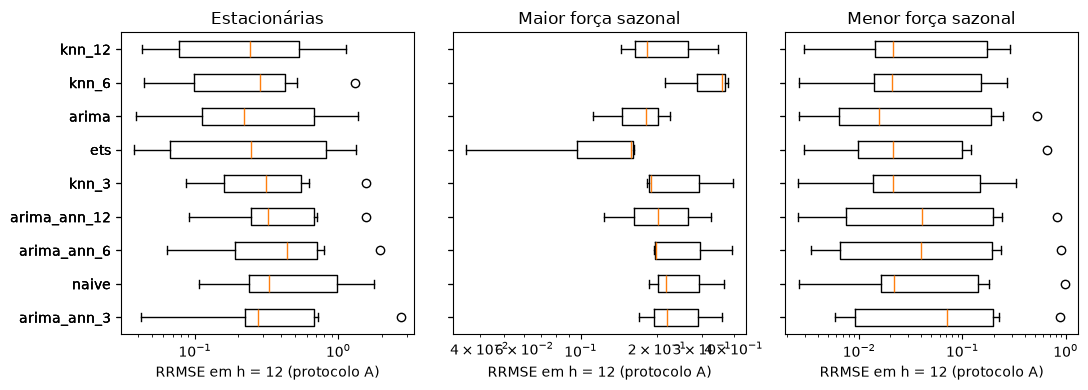

In [10]:
order = final[final.protocol == "A"].groupby("model").rrmse.mean().sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for ax, (category, title) in zip(axes, CAT.items(), strict=True):
    data = final[(final.protocol == "A") & (final.category == category)]
    ax.boxplot(
        [data.loc[data.model == m, "rrmse"] for m in order], vert=False, tick_labels=list(order)
    )
    ax.set(title=title, xlabel="RRMSE em h = 12 (protocolo A)", xscale="log")
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

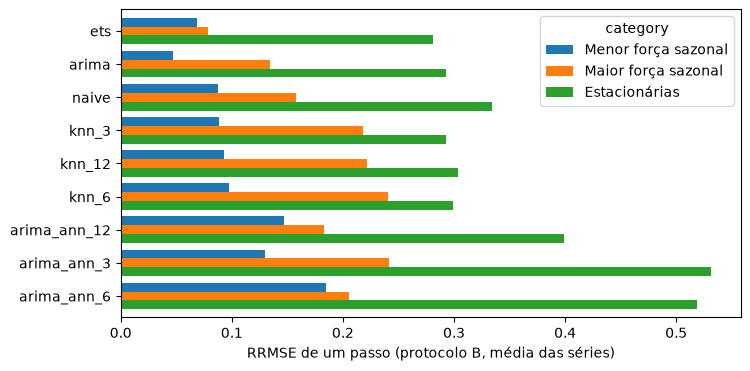

In [11]:
table_b = (
    final[final.protocol == "B"]
    .pivot_table(index="model", columns="category", values="rrmse")
    .rename(columns=CAT)
)
ax = table_b.loc[table_b.mean(axis=1).sort_values().index].plot.barh(figsize=(8, 4), width=0.8)
ax.set(xlabel="RRMSE de um passo (protocolo B, média das séries)", ylabel="")
ax.invert_yaxis()
plt.show()

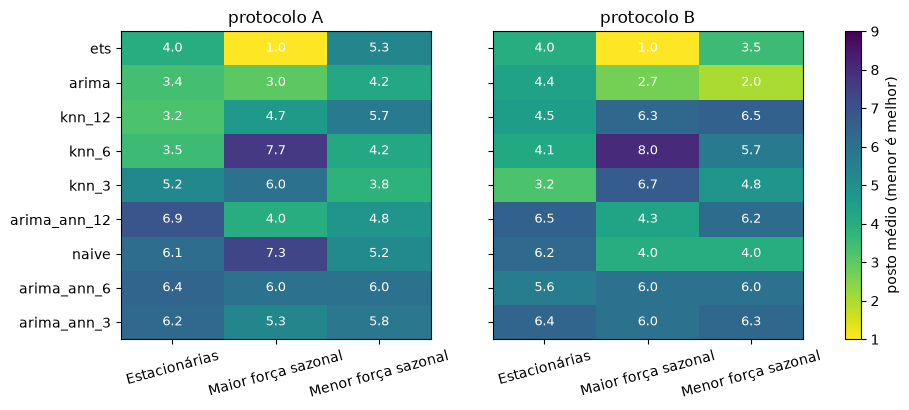

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = final.groupby("model").rrmse.mean().sort_values().index
for ax, protocol in zip(axes, ("A", "B"), strict=True):
    part = final[final.protocol == protocol]
    ranks = part.assign(rank=part.groupby("series_id").rrmse.rank())
    table = ranks.pivot_table(index="model", columns="category", values="rank").rename(columns=CAT)
    table = table.loc[order, list(CAT.values())]
    image = ax.imshow(table.to_numpy(), cmap="viridis_r", aspect="auto", vmin=1, vmax=len(order))
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=15)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_title(f"protocolo {protocol}")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(
                j, i, f"{table.iloc[i, j]:.1f}", ha="center", va="center", color="white", fontsize=9
            )
fig.colorbar(image, ax=axes, label="posto médio (menor é melhor)")
plt.show()

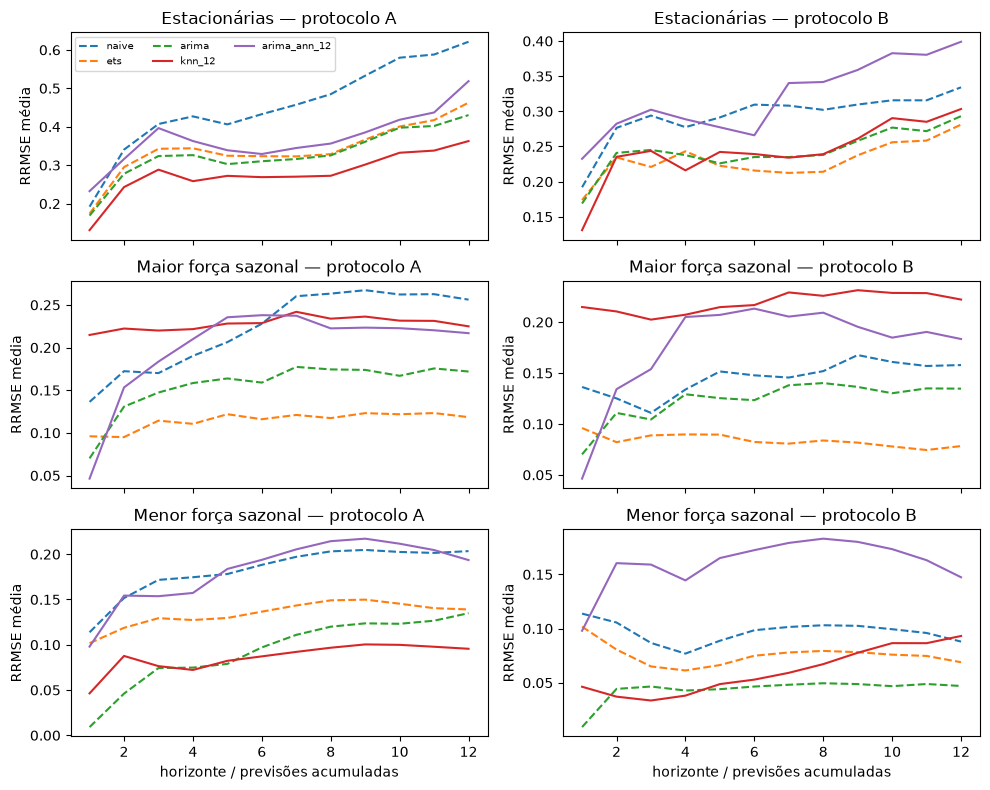

In [13]:
REFERENCE = ["naive", "ets", "arima", "knn_12", "arima_ann_12"]
curves = (
    metrics[metrics.model.isin(REFERENCE)]
    .groupby(["protocol", "category", "model", "h"])
    .rrmse.mean()
)
fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for row, (category, title) in enumerate(CAT.items()):
    for col, protocol in enumerate(("A", "B")):
        ax = axes[row, col]
        for model in REFERENCE:
            values = curves.loc[(protocol, category, model)]
            ax.plot(values.index, values, linestyle="--" if model in FIXED else "-", label=model)
        ax.set(title=f"{title} — protocolo {protocol}", ylabel="RRMSE média")
axes[0, 0].legend(ncol=3, fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("horizonte / previsões acumuladas")
fig.tight_layout()
plt.show()

### Efeito do número de lags

RRMSE médio em `h = 12` dos modelos de defasagem e dos híbridos com 3, 6 e 12 lags, por classe e protocolo. A linha tracejada é a persistência, referência de cada painel.

In [14]:
lagged = final[final.lags > 0]
lagged.pivot_table(
    index="structure", columns=["protocol", "category", "lags"], values="rrmse"
).round(4)

protocol            A                                                      \
category  nonseasonal                 seasonal                 stationary   
lags               3       6       12       3       6       12         3    
structure                                                                   
arima_ann      0.2080  0.2038  0.1935   0.2497  0.2617  0.2169     0.6395   
knn            0.0959  0.0876  0.0956   0.2561  0.3172  0.2249     0.4665   

protocol                            B                                   \
category                  nonseasonal                 seasonal           
lags           6       12          3       6       12       3       6    
structure                                                                
arima_ann  0.5875  0.5187      0.1302  0.1851  0.1474   0.2419  0.2058   
knn        0.3750  0.3628      0.0887  0.0972  0.0932   0.2180  0.2408   

protocol                                      
category          stationary                  
lags           12         3       6       12  
structure                                     
arima_ann  0.1834     0.5315  0.5188  0.3990  
knn        0.2221     0.2931  0.2990  0.3033

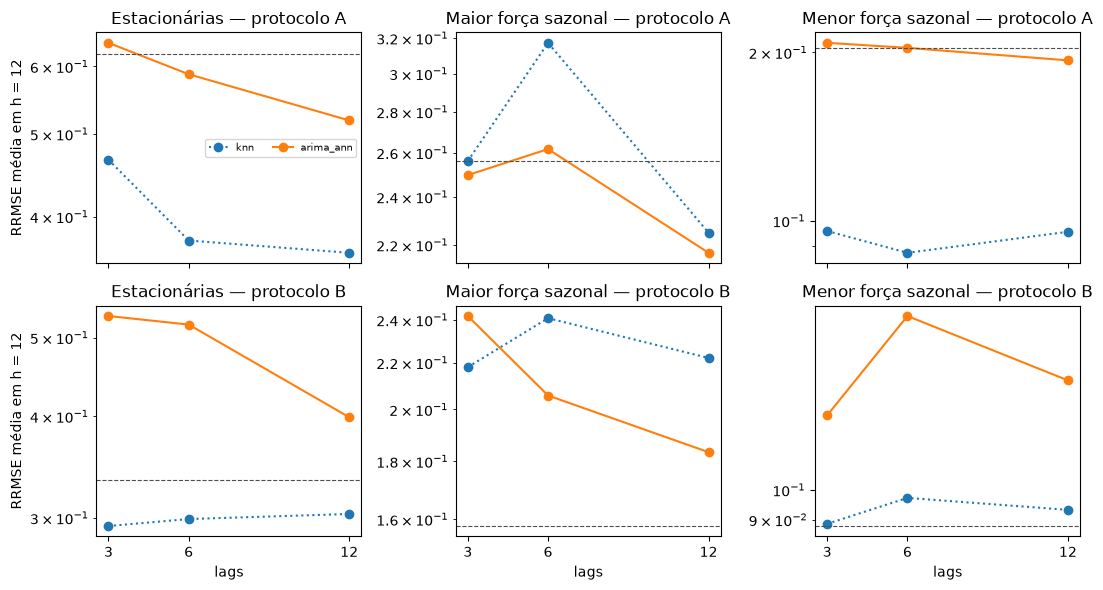

In [15]:
by_lag = lagged.groupby(["protocol", "category", "structure", "lags"]).rrmse.mean()
naive = final[final.model == "naive"].groupby(["protocol", "category"]).rrmse.mean()
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for row, protocol in enumerate(("A", "B")):
    for col, (category, title) in enumerate(CAT.items()):
        ax = axes[row, col]
        for structure in [*LAGGED, *(hybrid for hybrid, _ in PAIRS)]:
            values = by_lag.loc[(protocol, category, structure)]
            ax.plot(
                values.index,
                values,
                marker="o",
                linestyle=":" if structure in LAGGED else "-",
                label=structure,
            )
        ax.axhline(naive.loc[(protocol, category)], color="0.3", linestyle="--", linewidth=0.8)
        ax.set(title=f"{title} — protocolo {protocol}", xticks=LAGS, yscale="log")
        if col == 0:
            ax.set_ylabel("RRMSE média em h = 12")
axes[0, 0].legend(fontsize=7, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel("lags")
fig.tight_layout()
plt.show()

### Híbrido ARIMA–ANN contra o ARIMA

Ganho mediano em `h = 12`, ``100 · (RRMSE_base − RRMSE_híbrido) / RRMSE_base``, por protocolo, classe e janela do corretor (positivo quando o corretor ajuda), e as curvas de RRMSE da base e do híbrido em cada protocolo.

In [16]:
wide = metrics.pivot_table(
    index=["series_id", "category", "protocol", "h"], columns="model", values="rrmse"
)
gains = pd.concat(
    (100 * (wide[base] - wide[f"{hybrid}_{lags}"]) / wide[base])
    .rename("gain")
    .reset_index()
    .assign(hybrid=hybrid, lags=lags)
    for hybrid, base in PAIRS
    for lags in LAGS
)
gains[gains.h == H].pivot_table(
    index=["hybrid", "lags"], columns=["protocol", "category"], values="gain", aggfunc="median"
).round(2)

protocol                 A                               B                    
category       nonseasonal seasonal stationary nonseasonal seasonal stationary
hybrid    lags                                                                
arima_ann 3         -37.95   -51.13     -16.50     -126.60   -56.85     -51.62
          6         -20.21   -74.08     -35.59      -82.66   -58.08     -72.30
          12        -24.78   -10.32     -54.96     -118.18    -0.54     -58.42

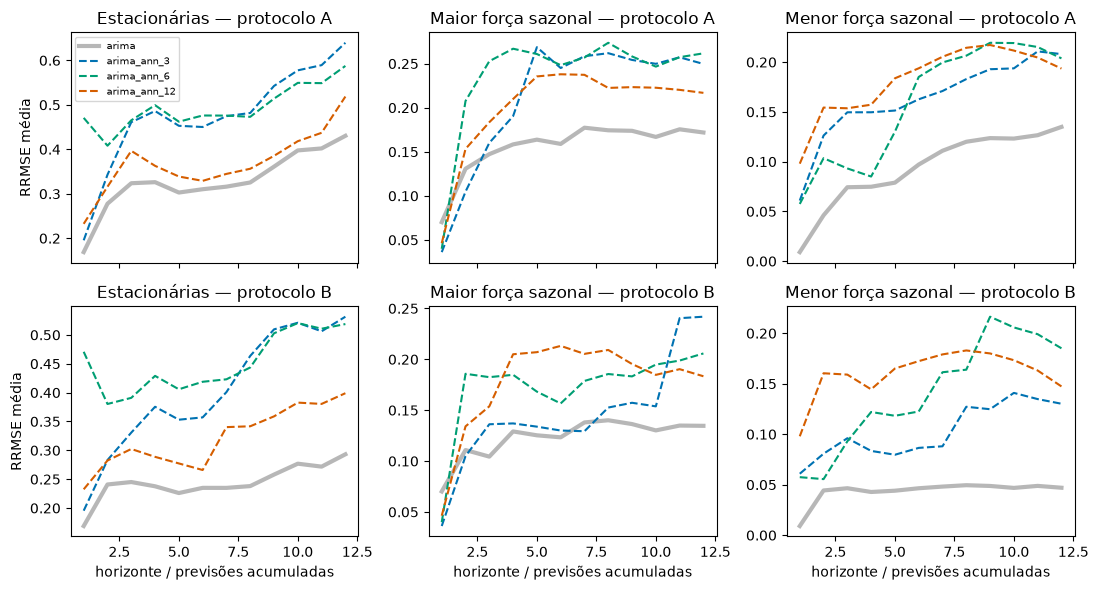

In [17]:
means = metrics.groupby(["model", "category", "protocol", "h"]).rrmse.mean()
hybrid, base = PAIRS[0]
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for row, protocol in enumerate(("A", "B")):
    for col, (category, title) in enumerate(CAT.items()):
        ax = axes[row, col]
        values = means.loc[(base, category, protocol)]
        ax.plot(values.index, values, color="0.3", linewidth=3, alpha=0.4, label=base)
        for lags, color in zip(LAGS, ("#0072B2", "#009E73", "#D55E00"), strict=True):
            values = means.loc[(f"{hybrid}_{lags}", category, protocol)]
            ax.plot(values.index, values, color=color, linestyle="--", label=f"{hybrid}_{lags}")
        ax.set_title(f"{title} — protocolo {protocol}")
        if col == 0:
            ax.set_ylabel("RRMSE média")
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("horizonte / previsões acumuladas")
fig.tight_layout()
plt.show()

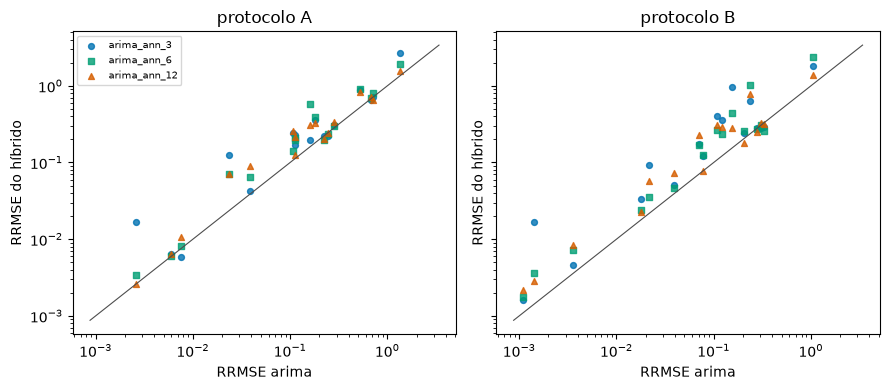

In [18]:
points = final.pivot_table(
    index=["series_id", "category", "protocol"], columns="model", values="rrmse"
).reset_index()
hybrids = [f"{hybrid}_{lags}" for lags in LAGS]
low, high = points[[base, *hybrids]].min().min() * 0.8, points[[base, *hybrids]].max().max() * 1.25
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, protocol in zip(axes, ("A", "B"), strict=True):
    part = points[points.protocol == protocol]
    ax.plot([low, high], [low, high], color="0.3", linewidth=0.8)
    for model, color, marker in zip(
        hybrids, ("#0072B2", "#009E73", "#D55E00"), ("o", "s", "^"), strict=True
    ):
        ax.scatter(
            part[base], part[model], s=18, color=color, marker=marker, alpha=0.8, label=model
        )
    ax.set(
        xscale="log",
        yscale="log",
        title=f"protocolo {protocol}",
        xlabel=f"RRMSE {base}",
        ylabel="RRMSE do híbrido",
    )
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 6. Diagnóstico e limites

Contrastes híbrido × base com o teste de Wilcoxon pareado por série, com a correção de Holm dentro de cada protocolo e classe (três contrastes, um por janela). Com 3 a 8 séries por classe, o menor p-valor possível é alto (com 3 séries, 0,25): os testes servem para relatar, não para afirmar superioridade. A janela do corretor não foi escolhida em validação: as três são mostradas lado a lado. O índice diário sintético ignora a frequência real. Horizontes longos, como 365 dias, exigem séries longas (o M4 Daily tem séries com mais de 4000 pontos); aqui algumas séries têm 60 observações, por isso o teste tem 12 passos.

In [19]:
contrasts = []
for (protocol, category), group in final.groupby(["protocol", "category"]):
    table = group.pivot_table(index="series_id", columns="model", values="rrmse")
    rows = []
    for hybrid, base in PAIRS:
        for lags in LAGS:
            paired = table[[f"{hybrid}_{lags}", base]].dropna()
            difference = paired[base] - paired[f"{hybrid}_{lags}"]
            p_value = 1.0 if (difference == 0).all() else float(wilcoxon(difference).pvalue)
            rows.append(
                {
                    "protocol": protocol,
                    "category": category,
                    "hybrid": hybrid,
                    "lags": lags,
                    "n": len(paired),
                    "p_value": p_value,
                    "median_gain_%": float((100 * difference / paired[base]).median()),
                    "wins": int((difference > 0).sum()),
                    "losses": int((difference < 0).sum()),
                }
            )
    frame = pd.DataFrame(rows)
    frame["p_holm"] = holm(frame.p_value.tolist())
    contrasts.append(frame)
pd.concat(contrasts, ignore_index=True).round(4)

,protocol,category,hybrid,lags,n,p_value,median_gain_%,wins,losses,p_holm
0,A,nonseasonal,arima_ann,3,6,0.4375,-37.9477,2,4,0.6562
1,A,nonseasonal,arima_ann,6,6,0.2188,-20.2060,1,5,0.6562
2,A,nonseasonal,arima_ann,12,6,0.3125,-24.7777,2,4,0.6562
3,A,seasonal,arima_ann,3,3,0.5000,-51.1312,1,2,1.0000
4,A,seasonal,arima_ann,6,3,0.5000,-74.0784,1,2,1.0000
5,A,seasonal,arima_ann,12,3,0.7500,-10.3177,1,2,1.0000
6,A,stationary,arima_ann,3,8,0.0391,-16.5043,1,7,0.0469
7,A,stationary,arima_ann,6,8,0.0078,-35.5936,0,8,0.0234
8,A,stationary,arima_ann,12,8,0.0234,-54.9617,1,7,0.0469
9,B,nonseasonal,arima_ann,3,6,0.0312,-126.6043,0,6,0.0938


## 7. Avaliação externa e custo

Todo número acima já é a leitura única do teste de cada modelo. O custo é o tempo de reajuste e avaliação por série, somado nos dois protocolos. Os ajustes de ARIMA ficam em cache por vetor de treino: o híbrido, avaliado depois da sua base, reaproveita a ordem já escolhida e pode sair mais barato que ela. O estudo completo leva poucos minutos.

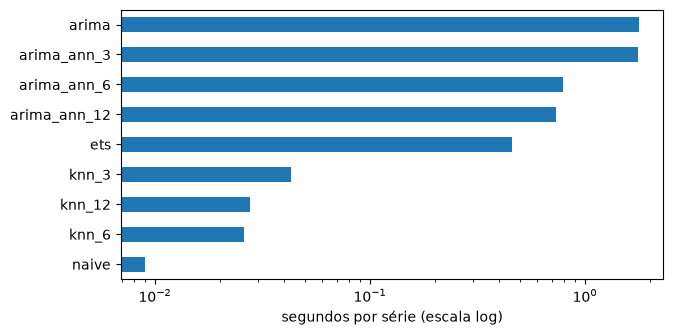

model
naive           0.009
knn_6           0.026
knn_12          0.028
knn_3           0.043
ets             0.457
arima_ann_12    0.730
arima_ann_6     0.786
arima_ann_3     1.764
arima           1.774
Name: seconds, dtype: float64

In [20]:
cost = final.groupby(["model", "series_id"]).seconds.sum().groupby("model").mean().sort_values()
ax = cost.plot.barh(figsize=(7, 3.5), log=True)
ax.set(xlabel="segundos por série (escala log)", ylabel="")
plt.show()
cost.round(3)

## 8. Leitura

- **Classes.** As 17 séries ficaram em 8 estacionárias, 6 de menor força sazonal e 3 de maior força sazonal. As estacionárias são as mais difíceis: o melhor RRMSE em `h = 12` fica perto de 0,28–0,36, contra 0,05–0,12 nas outras duas classes.
- **Protocolo A (12 passos de uma vez).** O KNN vence nas séries de menor força sazonal (`knn_6`, 0,088) e nas estacionárias (`knn_12`, 0,363); o ETS vence nas de maior força sazonal (0,118). Quase todos ficam abaixo da persistência em média; as exceções são o híbrido em várias janelas e o `knn_6` nas de maior força sazonal.
- **Protocolo B (um passo por vez).** Com o valor revelado a cada passo, os estatísticos passam à frente: ARIMA nas de menor força sazonal (0,047), ETS nas de maior força sazonal (0,078) e nas estacionárias (0,281). O erro de um passo é menor que o de A na maioria dos modelos.
- **Horizonte.** No protocolo A, o ARIMA é o melhor no primeiro passo nas séries de menor força sazonal (0,009), mas o erro acumulado cresce até 0,135 em 12 passos e o KNN o ultrapassa. O ETS degrada pouco com o horizonte.
- **Lags.** No protocolo A, o KNN com 12 lags é a melhor escolha nas estacionárias e nas de maior força sazonal; nas de menor força sazonal, 3, 6 e 12 ficam próximos. No híbrido, a janela de 12 resíduos é em geral a menos ruim.
- **Híbrido ARIMA–ANN.** O corretor piorou o ARIMA em todas as classes, protocolos e janelas: o ganho mediano vai de −0,5 % a −127 %. Nas estacionárias, no protocolo A, a perda continua significativa depois da correção de Holm (p entre 0,02 e 0,05); nas demais classes, com 3 a 6 séries, os testes não permitem conclusão. Uma explicação provável é que os resíduos do ARIMA tenham pouca estrutura a aprender, e a rede acabe somando ruído à previsão.
- **Custo.** O ARIMA é o modelo mais caro (cerca de 1,8 s por série nos dois protocolos); o KNN e a persistência custam centésimos de segundo. O híbrido parece mais barato que a base porque reaproveita o ajuste do ARIMA em cache.
- **Limites.** São poucas séries por classe, um único teste de 12 pontos e hiperparâmetros fixos, sem busca. Para decidir se um híbrido vale a pena numa série, use `compare_models`, que só aceita a complexidade extra quando ela passa nos critérios de validação.